# 2D convolution fundamentals

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/neural-networks/03-convolution-basics.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/>
</a>

A convolutional neural network (CNN) scans an image with a small matrix of numbers, called a **filter** or **kernel**. At each image location, it combines the nearby pixel values with the kernel weights to produce one output value. Reusing the same small kernel everywhere is the central idea behind convolution.

This notebook uses the grayscale Columbia Engineering logo to make one $3 \times 3$ calculation explicit, apply several hand-designed filters, and reproduce the same operation with PyTorch. In CNN libraries, this operation is technically cross-correlation; it is conventionally called convolution.


## What you will do

1. Load the same logo used in the 2D convolution explorer.
2. Calculate one local $3 \times 3$ filter response with NumPy.
3. Apply four filters to create four feature maps.
4. Perform the same operation with `torch.nn.Conv2d`.


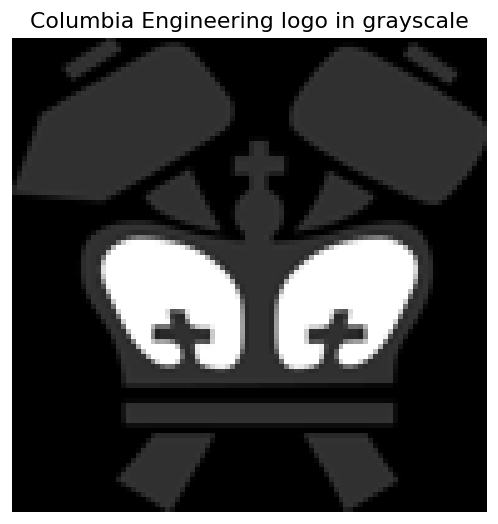

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

# Use the local course asset when available; the fallback also works in Colab.
local_logo_path = Path("../assets/columbia-engineering-logo.png")
logo_url = (
    "https://raw.githubusercontent.com/changyaochen/MECE4520/master/"
    "site/assets/columbia-engineering-logo.png"
)

if local_logo_path.exists():
    logo = Image.open(local_logo_path).convert("L")
else:
    with urlopen(logo_url) as response:
        logo = Image.open(BytesIO(response.read())).convert("L")

# A modest size keeps the calculation and figures quick to inspect.
image = np.asarray(logo.resize((96, 96)), dtype=float) / 255.0

figure, axis = plt.subplots(figsize=(4.5, 4.5))
axis.imshow(image, cmap="gray", vmin=0, vmax=1)
axis.set_title("Columbia Engineering logo in grayscale")
axis.axis("off")
figure.tight_layout()


## 1. One local $3 \times 3$ calculation

Let $X$ be the image and $K$ be a $3 \times 3$ kernel. Without padding, the response at output location $(i, j)$ is

$$
R_{i,j} = \sum_{u=0}^{2} \sum_{v=0}^{2} K_{u,v} X_{i+u, j+v}.
$$

The calculation is a local dot product: multiply the nine nearby pixels by the nine kernel weights, then add the results. Below, we apply a $3 \times 3$ mean kernel to a $5 \times 5$ logo crop with no padding. The kernel fits in three horizontal and three vertical locations, so the result has shape $3 \times 3$.


Local response:
 [[0.2  0.27 0.34]
 [0.47 0.55 0.61]
 [0.74 0.82 0.89]]


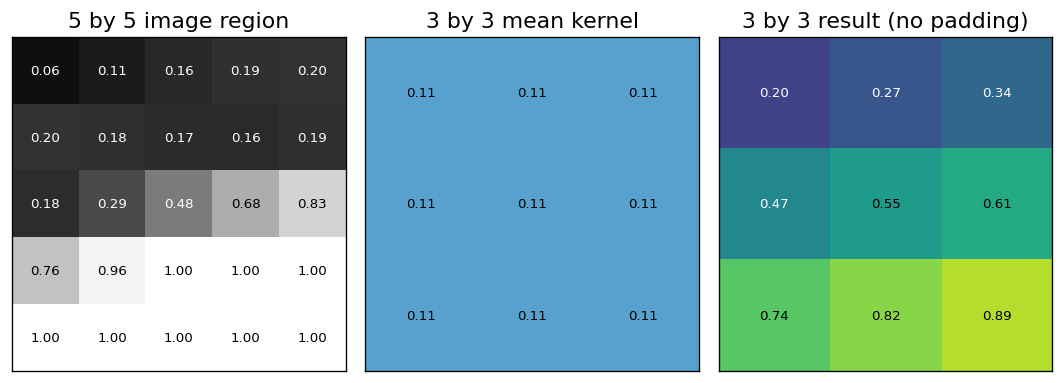

In [2]:
def valid_cross_correlation_2d(*, image: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    """Apply one 2D kernel to an image without padding.

    This is cross-correlation: the kernel slides without being flipped.
    PyTorch's Conv2d uses this same operation, although it calls the layer
    a convolution.

    Args:
        image: Grayscale image with shape (height, width).
        kernel: Filter weights with shape (kernel_height, kernel_width).

    Returns:
        The valid convolution response.
    """
    output_height = image.shape[0] - kernel.shape[0] + 1
    output_width = image.shape[1] - kernel.shape[1] + 1
    response = np.empty((output_height, output_width))
    for row in range(output_height):
        for column in range(output_width):
            patch = image[row : row + kernel.shape[0], column : column + kernel.shape[1]]
            # Elementwise multiplication followed by a sum: the patch-kernel dot product.
            response[row, column] = np.sum(patch * kernel)
    return response


mean_kernel = np.ones((3, 3)) / 9
response = valid_cross_correlation_2d(image=image, kernel=mean_kernel)

# This 5 by 5 crop crosses a dark-to-light edge in the logo.
row, column = 39, 64
local_image = image[row : row + 5, column : column + 5]
local_response = valid_cross_correlation_2d(image=local_image, kernel=mean_kernel)
print("Local response:\n", np.round(local_response, 2))

figure, axes = plt.subplots(1, 3, figsize=(9, 3.4))
panels = (
    (local_image, "5 by 5 image region", "gray", 0, 1),
    (mean_kernel, "3 by 3 mean kernel", "Blues", 0, 0.2),
    (local_response, "3 by 3 result (no padding)", "viridis", 0, 1),
)
for axis, (values, title, cmap, vmin, vmax) in zip(axes, panels):
    axis.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set(title=title, xticks=[], yticks=[])
    for patch_row in range(values.shape[0]):
        for patch_column in range(values.shape[1]):
            text_color = "white" if values[patch_row, patch_column] < (vmin + vmax) / 2 else "black"
            axis.text(patch_column, patch_row, f"{values[patch_row, patch_column]:.2f}",
                      ha="center", va="center", color=text_color, fontsize=8)
figure.tight_layout()


## 2. Four filters, four feature maps

Different kernels look for different local patterns. Here the kernels are chosen by hand: a blur averages nearby pixels, edge kernels respond to intensity changes in one direction, and the sharpen kernel emphasizes local differences. Each output image is a **feature map**.


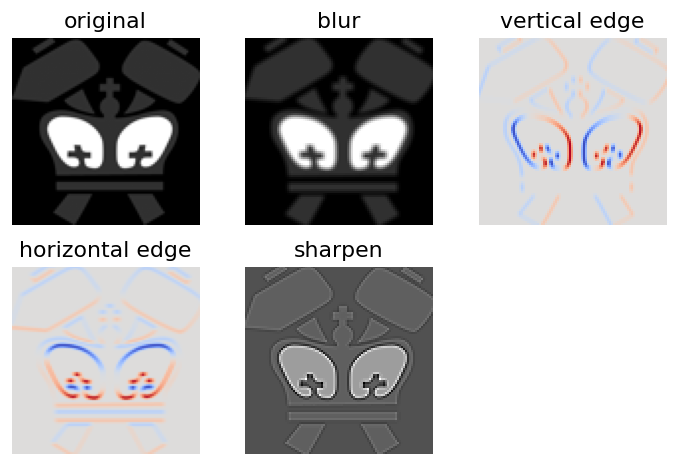

In [3]:
filters = {
    "blur": np.ones((3, 3)) / 9,
    "vertical edge": np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=float),
    "horizontal edge": np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=float),
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
}

feature_maps = {
    name: valid_cross_correlation_2d(image=image, kernel=kernel)
    for name, kernel in filters.items()
}

figure, axes = plt.subplots(2, 3, figsize=(6, 4))
axes = axes.ravel()
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("original")
axes[0].axis("off")

for axis, (name, feature_map) in zip(axes[1:], feature_maps.items()):
    if "edge" in name:
        limit = np.max(np.abs(feature_map))
        axis.imshow(feature_map, cmap="coolwarm", vmin=-limit, vmax=limit)
    else:
        axis.imshow(feature_map, cmap="gray")
    axis.set_title(name)
    axis.axis("off")

axes[-1].axis("off")
figure.tight_layout()


## 3. The same operation with PyTorch

`torch.nn.Conv2d` expects a four-dimensional input: `(batch, channel, height, width)`. The two `unsqueeze` calls below add a batch dimension and a grayscale-channel dimension. We copy a hand-designed vertical-edge kernel into the layer so that its output can be compared directly with our NumPy implementation.


In [4]:
vertical_kernel = filters["vertical edge"]

# One grayscale image: (height, width) -> (batch=1, channels=1, height, width).
image_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

# One output channel, one input channel, and a 3 by 3 kernel; no learned bias here.
convolution = torch.nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    bias=False,
)

# Replace PyTorch's random initial weights with our hand-designed kernel.
with torch.no_grad():
    convolution.weight.copy_(torch.tensor(vertical_kernel, dtype=torch.float32).unsqueeze(0).unsqueeze(0))

torch_response = convolution(image_tensor).squeeze().detach().numpy()
numpy_response = feature_maps["vertical edge"]

print("Input tensor shape:", tuple(image_tensor.shape))
print("Kernel tensor shape:", tuple(convolution.weight.shape))
print("Output tensor shape:", tuple(torch_response.shape))
print("NumPy and PyTorch agree:", np.allclose(torch_response, numpy_response))


Input tensor shape: (1, 1, 96, 96)
Kernel tensor shape: (1, 1, 3, 3)
Output tensor shape: (94, 94)
NumPy and PyTorch agree: True


## Takeaway

A CNN keeps the local-dot-product structure shown here, but learns many useful kernels from labeled images rather than setting them by hand. The same kernel is shared over the whole image, so the model can recognize a useful local pattern wherever it appears. Next, we use this idea to classify handwritten digits.
